Dados Prontos:
                          Nome  Valor_Recebido         Cidade Status
0      DAVI ERNESTIDES MARTINS          1320.0  FLORIANÓPOLIS  Saque
1      DAVI ERNESTIDES MARTINS          1320.0  FLORIANÓPOLIS  Saque
2      DAVI ERNESTIDES MARTINS          1320.0  FLORIANÓPOLIS  Saque
3      DAVI ERNESTIDES MARTINS          1320.0  FLORIANÓPOLIS  Saque
4  FABIO ALEXANDRE CUNHA PARDO          1320.0  FLORIANÓPOLIS  Saque


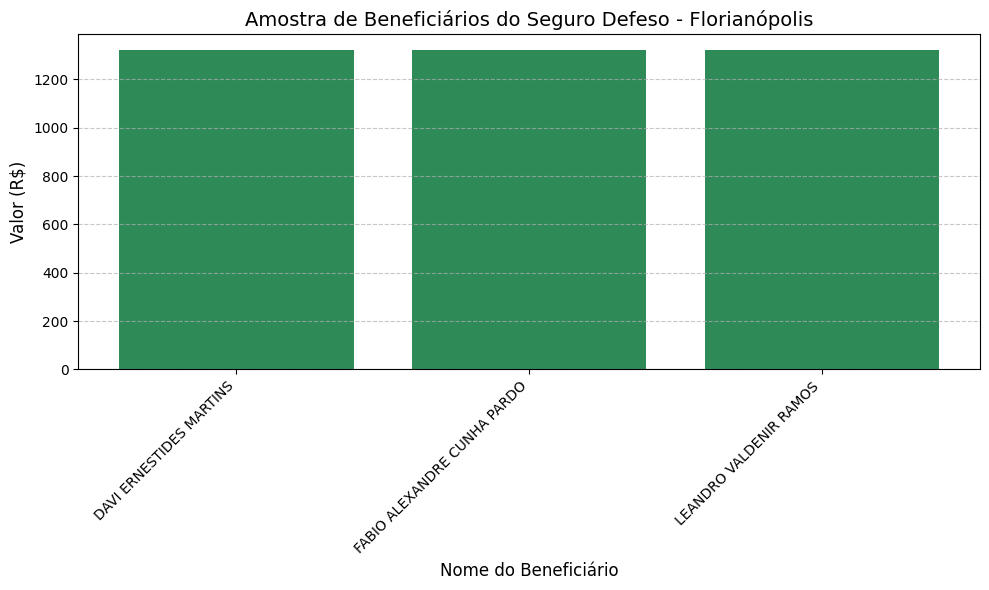

In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import userdata

headers = {
    "chave-api-dados": userdata.get('chave-api-dados')
}
link_api = "https://api.portaldatransparencia.gov.br/api-de-dados/seguro-defeso-beneficiario-por-municipio"
parametros = {
    "mesAno": "202306",
    "codigoIbge": "4205407", # Florianópolis
    "pagina": "1"
}

resposta = requests.get(link_api, headers=headers, params=parametros)

if resposta.status_code == 200:

    dados_json = resposta.json()

    df = pd.json_normalize(dados_json)
    colunas_interesse = {
        'pessoaSeguroDefeso.nome': 'Nome',
        'valor': 'Valor_Recebido',
        'municipio.nomeIBGE': 'Cidade',
        'situacao': 'Status'
    }
    df_filtrado = df[list(colunas_interesse.keys())].rename(columns=colunas_interesse)

    df_filtrado['Valor_Recebido'] = pd.to_numeric(df_filtrado['Valor_Recebido'])

    print("Dados Prontos:")
    print(df_filtrado.head())

    plt.figure(figsize=(10, 6))
    top_10 = df_filtrado.head(10)

    plt.bar(top_10['Nome'], top_10['Valor_Recebido'], color='seagreen')

    plt.title('Amostra de Beneficiários do Seguro Defeso - Florianópolis', fontsize=14)
    plt.xlabel('Nome do Beneficiário', fontsize=12)
    plt.ylabel('Valor (R$)', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.savefig('grafico_seguro_defeso.png')
    plt.show()

else:
    print(f"Erro ao acessar API: {resposta.status_code}")

In [ ]:
!pip install tabula-py

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 67.1 MB/s eta 0:00:00


In [ ]:
import tabula
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import userdata

lista_tabelas = tabula.read_pdf("remume_versao_2024.pdf", pages="all")
print(f"O PDF tem {len(lista_tabelas)} tabelas")

df_completo = pd.concat(lista_tabelas, ignore_index=True)
df_completo.head(10)


O PDF tem 28 tabelas


,Item,Medicamento,Apresentação,Local de acesso,Unnamed: 0,(Controlado Port.\r344/98 - Lista C1),288 mg\rvalproato de\rsódio)\rCápsula,Unnamed: 1,Unnamed: 2,25,...,"edicamentos do CESAF são dispensados na Farmácia Estratégica, localizada no Centro",e Vigilância em Saúde. Alguns programas estratégicos do Ministério da Saúde atendido,o município de Criciúma,► COVID-19 - Nirmatrelvir/Ritonavir (NMV/r,Unnamed: 3,pacientes com HIV/AIDS e\rpara o tratamento de IST,Exclusivo para tratamento de\rtoxoplasmose.,DISTRITO SANTA LUZIA:\rUBS Vila Manaus: 3445-8479\rUBS Mineiras: 3445-8454\rUBS Mãe Luzia: 3445-8458\rUBS Mina União: 3445-8482\rUBS Nova Esperança: 3445-8472\rUBS São Defende: 3445-8469\rUBS Vila Belmiro: 3445-8489\r\rDISTRITO BOA VISTA:\rUBS Pinheirinho/Alto: 3445-8846 /\r3437-0919\rUBS Paraíso: 3445-8480\rUBS Santo Antônio: 3445-8467\rUBS Santa Augusta: 3445-8465\rUBS Sangão: 3445-8486\rUBS São Roque: 3445-8487\rUBS Verdinho: 3445-8485,DISTRITO RIO MAINA:\rUBS Colonial: 3439-8561\rUBS Laranjinha: 3445-8457\rUBS Metropol: 3445-8483\rUBS São Marcos:\r3445-8452\rUBS Vila Francesa:\r3445-8473\rUBS Vila Zuleima:\r3445-8475\r\rDISTRITO CENTRO:\rUBS Maria Céu: 3438-0727\rUBS Milanese: 3445-8422\rUBS Mina do Toco:\r3445-8484\rUBS São Luiz: 3445-8462\rUBS São Simão: 3445-8471,DISTRITO PRÓSPERA:\rUBS Ana Maria: 3445-8450\rUBS Argentina: 3445-8451\rUBS CSU: 3445-8456\rUBS Cristo Redentor: 3445-8455\rUBS Linha Batista: 3445-8478\rUBS Nossa Senhora da Salete:\r3445-8461\rUBS Renascer: 3445-8460\rUBS Vila Rica/Imigrantes:\r3445-8474\rUBS Brasília: 3462-1340\rUBS Morro Estevão: 3461-8450\rUBS Primeira Linha: 3445-8404
0,NaN,NaN,NaN,NaN,Classificação e tipo de,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,receita,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,600 mg,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,- Expectorante,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,granulado,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,1.0,Acetilcisteína,NaN,- Farmácias Distritais,- Receituário simples,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,envelopes com,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,5 g,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,Aciclovir,200 mg,- Farmácias Distritais,- Antiviral,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
